# 06 – Vergleich: DWD gegen jedes Modell

Alle Modelle in eine Tabelle bringen (°C, Niederschlag in mm pro 6 h, Lead Times +6 h bis +240 h), mit den
DWD-Messungen verbinden und den Fehler vergleichen. Fehler = Vorhersage − Messung.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "../data/full_datasets"
LEAD_TIMES = list(range(6, 241, 6))
MODELS = ["AIFS", "GraphCast", "IFS", "GFS"]
COLORS = {"AIFS": "#2a78d6", "GraphCast": "#1baf7a", "IFS": "#eb6834", "GFS": "#eda100"}

## DWD laden

Niederschlag: Summe der 6 Stunden vor dem Zeitpunkt (wie bei den Modellen).

In [2]:
temp = pd.read_csv(f"{DATA_DIR}/dwd_01975_air_temperature_hourly.csv", parse_dates=["time"])
rain = pd.read_csv(f"{DATA_DIR}/dwd_01975_rainfall_hourly.csv", parse_dates=["time"])

dwd = pd.DataFrame({"valid_time": temp["time"], "obs_t2m": temp["TT_TU"]})
# Summe der letzten 6 Stunden
dwd["obs_precip"] = rain["R1"].rolling(6, min_periods=6).sum()

## Modelle laden und vereinheitlichen

AIFS, IFS und GFS haben verschiedene Schrittweiten (6 h, 3 h, 1 h). Die Niederschlagsrate (mm/s) wird pro Schritt in
mm umgerechnet und auf 6-h-Fenster summiert. GraphCast: Kelvin → °C, Meter → mm, Fehlwerte (9,97·10³⁶) → NaN.

In [3]:
def prepare_dynamical(path, model):
    df = pd.read_csv(path, parse_dates=["init_time", "valid_time"])
    df = df.sort_values(["init_time", "lead_time_h"])

    # Rate mal Schrittlänge ergibt mm
    df["step_h"] = df.groupby("init_time")["lead_time_h"].diff()
    df["precip_mm"] = df["precipitation_surface"] * df["step_h"] * 3600

    # Schritte zu 6-h-Fenstern summieren
    df["window_h"] = np.ceil(df["lead_time_h"] / 6) * 6
    precip = df.groupby(["init_time", "window_h"])["precip_mm"].sum().reset_index()
    precip.columns = ["init_time", "lead_time_h", "precip"]

    out = df[["init_time", "lead_time_h", "valid_time", "temperature_2m"]].merge(precip)
    out = out.rename(columns={"temperature_2m": "t2m"})
    out["model"] = model
    return out


def prepare_graphcast(path):
    df = pd.read_csv(path, parse_dates=["init_time", "time"])
    df = df.rename(columns={"time": "valid_time"})
    # Fehlwerte durch NaN ersetzen
    df.loc[df["t2"] > 1000, "t2"] = np.nan
    df.loc[df["apcp"] > 1000, "apcp"] = np.nan

    df["t2m"] = df["t2"] - 273.15
    df["precip"] = (df["apcp"] * 1000).clip(lower=0)
    df["lead_time_h"] = (df["valid_time"] - df["init_time"]).dt.total_seconds() / 3600
    df["model"] = "GraphCast"
    return df[["init_time", "lead_time_h", "valid_time", "t2m", "precip", "model"]]


forecasts = pd.concat([
    prepare_dynamical(f"{DATA_DIR}/aifs_single_hamburg_t2m_precip.csv", "AIFS"),
    prepare_graphcast(f"{DATA_DIR}/graphcast_ifs_hamburg_t2m_precip.csv"),
    prepare_dynamical(f"{DATA_DIR}/ifs_control_hamburg_t2m_precip.csv", "IFS"),
    prepare_dynamical(f"{DATA_DIR}/gfs_hamburg_t2m_precip.csv", "GFS"),
])
forecasts = forecasts[forecasts["lead_time_h"].isin(LEAD_TIMES)]

## Mit DWD verbinden

Die fertige Tabelle speichern wir für die Modellierung.

In [4]:
df = forecasts.merge(dwd, on="valid_time")
df["abs_err_t2m"] = (df["t2m"] - df["obs_t2m"]).abs()

df.to_csv("../data/prepared/forecasts_vs_dwd.csv", index=False)
df.head()

,init_time,lead_time_h,valid_time,t2m,precip,model,obs_t2m,obs_precip,abs_err_t2m
0,2024-04-01,6.0,2024-04-01 06:00:00,6.09375,0.057292,AIFS,7.0,0.0,0.90625
1,2024-04-01,12.0,2024-04-01 12:00:00,8.62500,4.676056,AIFS,10.0,4.1,1.37500
2,2024-04-01,18.0,2024-04-01 18:00:00,8.43750,8.363342,AIFS,9.7,9.0,1.26250
3,2024-04-01,24.0,2024-04-02 00:00:00,8.06250,2.286530,AIFS,9.3,3.0,1.23750
4,2024-04-01,30.0,2024-04-02 06:00:00,7.96875,0.217581,AIFS,8.8,0.0,0.83125


## DWD gegen jedes Modell

Links: Vorhersage gegen Messung für +24 h bis +42 h (Tag 2). Je näher an der Diagonale, desto besser.
Rechts: mittlerer absoluter Temperaturfehler (MAE) nach Lead Time. Die Kurve zackt, weil alle Läufe um 00 UTC starten
(+12 h ist immer mittags, +24 h immer nachts).

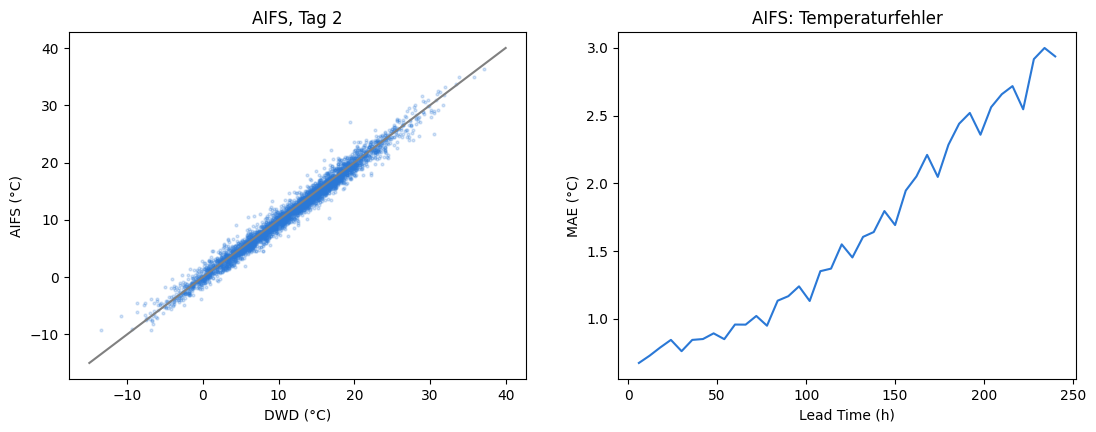

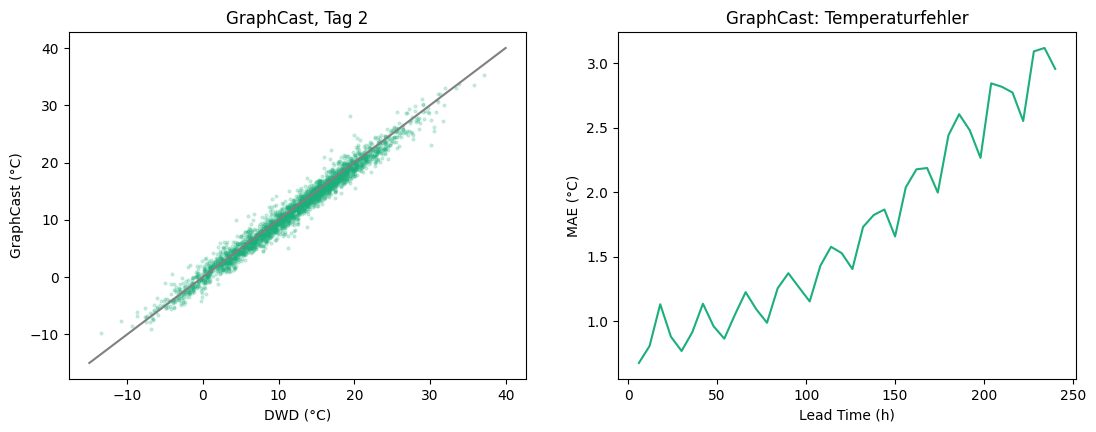

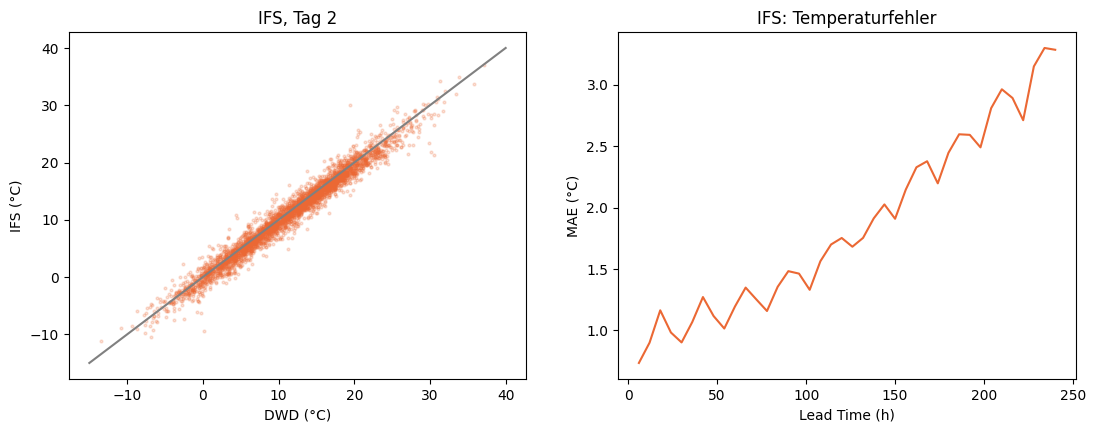

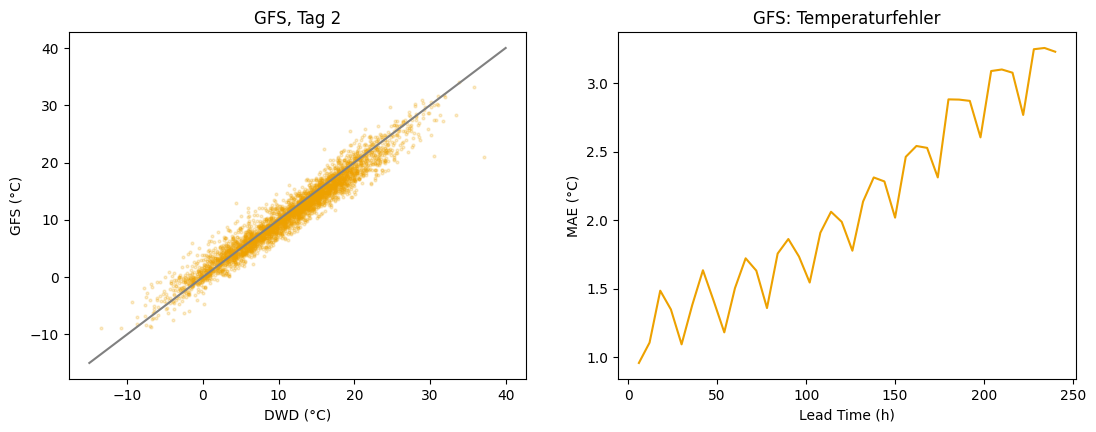

In [5]:
for model in MODELS:
    data = df[df["model"] == model]
    day2 = data[data["lead_time_h"].between(24, 42)]
    mae = data.groupby("lead_time_h")["abs_err_t2m"].mean()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].scatter(day2["obs_t2m"], day2["t2m"], s=4, alpha=0.2, color=COLORS[model])
    axes[0].plot([-15, 40], [-15, 40], color="gray")
    axes[0].set_xlabel("DWD (°C)")
    axes[0].set_ylabel(f"{model} (°C)")
    axes[0].set_title(f"{model}, Tag 2")
    axes[1].plot(mae.index, mae.values, color=COLORS[model])
    axes[1].set_xlabel("Lead Time (h)")
    axes[1].set_ylabel("MAE (°C)")
    axes[1].set_title(f"{model}: Temperaturfehler")
    plt.show()

## Alle Modelle zusammen

Nur Starttage, an denen alle vier Modelle einen Lauf haben (GraphCast hat Lücken, siehe Notebook 03).
Rechts: Anteil der 6-h-Fenster mit Regen (≥ 0,1 mm), vorhergesagt und gemessen.

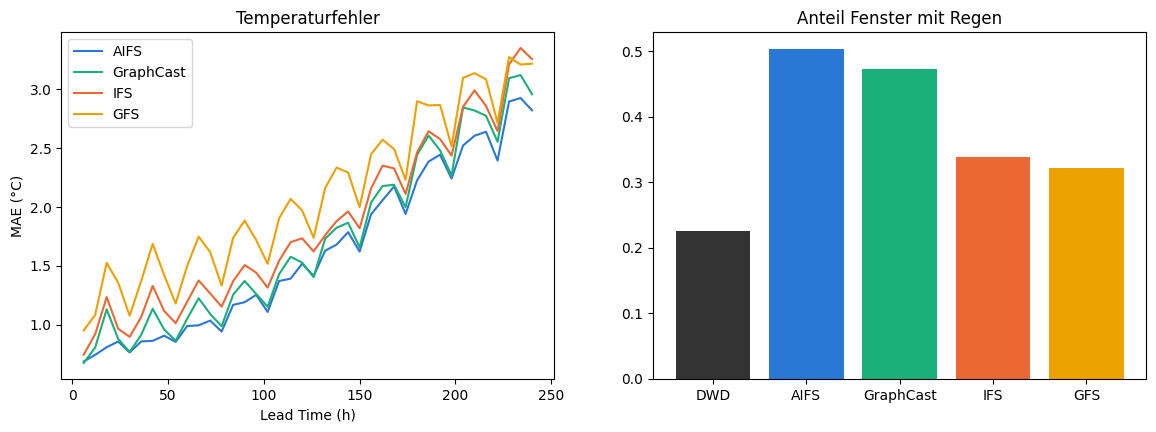

model,AIFS,GraphCast,IFS,GFS
lead_time_h,,,,
24.0,0.86,0.88,0.97,1.36
120.0,1.52,1.53,1.73,1.97
240.0,2.82,2.96,3.26,3.22


In [6]:
models_per_day = df.groupby("init_time")["model"].nunique()
common = df[df["init_time"].isin(models_per_day[models_per_day == 4].index)]

mae = common.groupby(["lead_time_h", "model"])["abs_err_t2m"].mean().unstack()
wet = (common["precip"] >= 0.1).groupby(common["model"]).mean()
dwd_wet = (common.loc[common["model"] == "AIFS", "obs_precip"] >= 0.1).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for model in MODELS:
    axes[0].plot(mae.index, mae[model], color=COLORS[model], label=model)
axes[0].set_xlabel("Lead Time (h)")
axes[0].set_ylabel("MAE (°C)")
axes[0].set_title("Temperaturfehler")
axes[0].legend()
axes[1].bar(["DWD"] + MODELS, [dwd_wet] + [wet[m] for m in MODELS],
            color=["#333333"] + [COLORS[m] for m in MODELS])
axes[1].set_title("Anteil Fenster mit Regen")
plt.show()

mae.loc[[24, 120, 240], MODELS].round(2)

## Erkenntnisse

- Der Temperaturfehler wächst bei allen Modellen mit der Lead Time, von etwa 1 °C (+24 h) auf etwa 3 °C (+240 h).
- Die KI-Modelle (AIFS, GraphCast) sind bei der Temperatur durchgehend etwas besser als IFS und deutlich besser als GFS.
- Die KI-Modelle sagen viel zu oft Regen voraus (in etwa der Hälfte der Fenster, gemessen: gut 20 %). Die Physikmodelle
  liegen näher an der Messung. Erste Hypothese: KI „verschmiert“ Niederschlag zu häufigem leichtem Regen.
- Ob KI auch Temperatur-Extreme glättet, prüfen wir in der Modellierungsphase.